In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
from collections import OrderedDict
from datasets import load_dataset
from torch.utils.data import DataLoader
from scipy.sparse import csr_matrix
from sklearn.metrics import classification_report
import torch.nn as nn
from nltk.util import bigrams
from collections import Counter

import experiment
import clslib
import analysis
import mmlp

In [2]:
dataset = load_dataset("stanfordnlp/sst2")
# temp_train_df = dataset["train"].to_pandas()
# temp_val_df = dataset["validation"].to_pandas()
# dataset_df = pd.concat([temp_train_df, temp_val_df], ignore_index=True).drop(columns=['idx'])
# train_df, val_df, test_df = np.split(dataset_df, [int(0.8 * len(dataset_df)), int(0.9 * len(dataset_df))])

# train_dataset = Dataset.from_pandas(train_df)
# val_dataset = Dataset.from_pandas(val_df)
# test_dataset = Dataset.from_pandas(test_df)
train_dataset = dataset["train"]
test_dataset = dataset["validation"]

In [3]:
vocab_size = 1000
top_bigrams_num = 10000
min_frequency = 2
my_seeds = [0]
num_folds = 5
my_cross_validation_sets = []
results_folder = Path("./results")
results_folder.mkdir(exist_ok=True)

for seed in my_seeds:
    my_cross_validation_sets.append(
        experiment.cross_validation_split(
            # we pair the texts with their labels
            pairs=list(zip(train_dataset["sentence"], train_dataset["label"])), 
            k=num_folds,
            seed=seed
        )
    )

bpe_tokenizer = experiment.train_bpe_tokenizer(train_dataset["sentence"], vocab_size, min_frequency)
# tokenizer.save(f"{results_folder}/BPE_tokenizer_vs_{vocab_size}_mf_{min_frequency}.json")

corpus_bigrams = []
for text in train_dataset["sentence"]:
    tokens = bpe_tokenizer.encode(text).tokens
    corpus_bigrams.extend(bigrams(tokens))

top_bigrams = [item for item, _ in Counter(corpus_bigrams).most_common(top_bigrams_num)]
bigram_encoder = clslib.BagOfBigrams(top_bigrams, bpe_tokenizer)

my_classifiers = OrderedDict()

In [4]:
hidden_dim=128
hidden_dim_2=128
dropout=0.1
batch_size=64
learning_rate=1e-3
weight_decay=1e-4
num_epochs=10
device='cpu'

my_classifiers['modMLP_bigram-enc'] = []

for run, seed in enumerate(my_seeds):    
    run_folder = f"{results_folder}/modMLP_bigram-enc/seed-{seed}"
    my_classifiers['modMLP_bigram-enc'].append(
        experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            encoder=bigram_encoder,
            model_option='mmlp',
            save_to=run_folder,
            mmlp_args={
                'hidden_dim': hidden_dim,
                'hidden_dim_2': hidden_dim_2,
                'dropout': dropout, 
                'batch_size': batch_size, 
                'learning_rate': learning_rate, 
                'weight_decay': weight_decay, 
                'num_epochs': num_epochs,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 253.013 seconds
Dataloader done! Time taken: 3.731 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

c:\Users\PCUser\Desktop\UvA\NLP\NLP-Assignment-1\mmlp.py:75: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\Context.cpp:855.)
  return torch.sparse_coo_tensor(indices, values, size=x.shape).coalesce()


Epoch 01 | train loss: 0.4022 | train acc: 0.8112 | val loss: 0.2677 | val acc: 0.8931
Epoch 02 | train loss: 0.1942 | train acc: 0.9237 | val loss: 0.2443 | val acc: 0.9052
Epoch 03 | train loss: 0.1280 | train acc: 0.9509 | val loss: 0.2458 | val acc: 0.9089
Epoch 04 | train loss: 0.0880 | train acc: 0.9661 | val loss: 0.2817 | val acc: 0.9102
Epoch 05 | train loss: 0.0658 | train acc: 0.9736 | val loss: 0.3355 | val acc: 0.9102
Epoch 06 | train loss: 0.0545 | train acc: 0.9770 | val loss: 0.3658 | val acc: 0.9120
Epoch 07 | train loss: 0.0467 | train acc: 0.9800 | val loss: 0.3823 | val acc: 0.9104
Epoch 08 | train loss: 0.0429 | train acc: 0.9809 | val loss: 0.3962 | val acc: 0.9126
Epoch 09 | train loss: 0.0383 | train acc: 0.9826 | val loss: 0.4300 | val acc: 0.9122
Epoch 10 | train loss: 0.0366 | train acc: 0.9828 | val loss: 0.4381 | val acc: 0.9116
Training done! Time taken: 134.999 seconds
Transforming documents...
Document transformation done! Time taken: 258.449 seconds
Dat

  0%|          | 0/10 [00:00<?, ?it/s]

... (3 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.4003 | train acc: 0.8092 | val loss: 0.2878 | val acc: 0.8865
Epoch 02 | train loss: 0.1915 | train acc: 0.9257 | val loss: 0.2596 | val acc: 0.9033
Epoch 03 | train loss: 0.1273 | train acc: 0.9520 | val loss: 0.2678 | val acc: 0.9061
Epoch 04 | train loss: 0.0886 | train acc: 0.9660 | val loss: 0.2966 | val acc: 0.9100
Epoch 05 | train loss: 0.0640 | train acc: 0.9745 | val loss: 0.3591 | val acc: 0.9086
Epoch 06 | train loss: 0.0519 | train acc: 0.9780 | val loss: 0.3890 | val acc: 0.9089
Epoch 07 | train loss: 0.0454 | train acc: 0.9801 | val loss: 0.4370 | val acc: 0.9075
Epoch 08 | train loss: 0.0415 | train acc: 0.9819 | val loss: 0.4350 | val acc: 0.9080
Epoch 09 | train loss: 0.0373 | train acc: 0.9829 | val loss: 0.4726 | val acc: 0.9068
Epoch 10 | train loss: 0.0359 | train acc: 0.9839 | val loss: 0.4955 | val acc: 0.9042
Training done! Time taken: 184.233 seconds
Transforming documents...
Document transformation done! Time taken: 293.686 seconds
Dat

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.3987 | train acc: 0.8144 | val loss: 0.2712 | val acc: 0.8894
Epoch 02 | train loss: 0.1919 | train acc: 0.9257 | val loss: 0.2587 | val acc: 0.8993
Epoch 03 | train loss: 0.1263 | train acc: 0.9521 | val loss: 0.2621 | val acc: 0.9058
Epoch 04 | train loss: 0.0874 | train acc: 0.9663 | val loss: 0.2906 | val acc: 0.9071
Epoch 05 | train loss: 0.0648 | train acc: 0.9734 | val loss: 0.3198 | val acc: 0.9073
Epoch 06 | train loss: 0.0543 | train acc: 0.9775 | val loss: 0.3918 | val acc: 0.9062
Epoch 07 | train loss: 0.0448 | train acc: 0.9806 | val loss: 0.3881 | val acc: 0.9072
Epoch 08 | train loss: 0.0411 | train acc: 0.9815 | val loss: 0.4405 | val acc: 0.9076
Epoch 09 | train loss: 0.0392 | train acc: 0.9825 | val loss: 0.4207 | val acc: 0.9070
Epoch 10 | train loss: 0.0360 | train acc: 0.9832 | val loss: 0.4584 | val acc: 0.9071
Training done! Time taken: 146.741 seconds


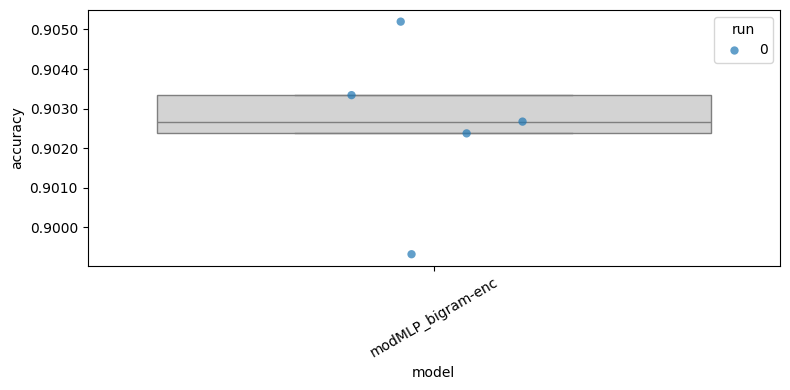

In [5]:
analysis.plot_box_and_points(analysis.make_data_frame(my_classifiers))

In [6]:
testing_sentences = test_dataset["sentence"]
testing_vectors = [bigram_encoder(text) for text in testing_sentences]
testing_labels = test_dataset["label"]
X_test_sparse = csr_matrix(testing_vectors)
test_dataset_sparse = mmlp.SparseDataset(X_test_sparse, testing_labels)

test_loader = DataLoader(
        test_dataset_sparse,
        batch_size=batch_size,
        shuffle=False,
        collate_fn=mmlp.sparse_collate
    )

criterion = nn.BCEWithLogitsLoss()

for run, seed in enumerate(my_seeds):
    for fold in range(num_folds):    
        model_folder = f"{results_folder}/modMLP_bigram-enc/seed-{seed}/fold-{fold}/model"
        model = mmlp.load(model_folder)

        mmlp.evaluate(model, test_loader, criterion, device)
        test_metrics, preds = mmlp.evaluate(model, test_loader, criterion, device)
        print(test_metrics)
        print(classification_report(testing_labels, preds))

{'loss': 0.6231916377303797, 'accuracy': 0.8027522935779816}
              precision    recall  f1-score   support

           0       0.81      0.78      0.80       428
           1       0.80      0.82      0.81       444

    accuracy                           0.80       872
   macro avg       0.80      0.80      0.80       872
weighted avg       0.80      0.80      0.80       872

{'loss': 0.6846740278628988, 'accuracy': 0.7970183486238532}
              precision    recall  f1-score   support

           0       0.80      0.78      0.79       428
           1       0.79      0.81      0.80       444

    accuracy                           0.80       872
   macro avg       0.80      0.80      0.80       872
weighted avg       0.80      0.80      0.80       872

{'loss': 0.606264487865868, 'accuracy': 0.8084862385321101}
              precision    recall  f1-score   support

           0       0.81      0.80      0.80       428
           1       0.81      0.82      0.81       444



In [7]:
# save results
Path("metrics").mkdir(exist_ok=True)

df = analysis.make_data_frame(my_classifiers)
df["seed"] = df["run"].map(dict(enumerate(my_seeds)))

df.to_csv(f"metrics/{next(iter(my_classifiers))}.csv", index=False)